In [2]:
#Cargar dataset: 
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Ya podemos diferencias tipo de variables: 
Variables numericas: stars, reviews, price, boughtInLastMonth
Variables categóricas: asin (identificador Amazon), title, category
Variable Booleana: isBestSeller

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [5]:
df.shape

(2443651, 9)

In [7]:
#Vamos a comprobar si hay nulos
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [8]:
#Vamos a comprobar si hay duplicados

df.duplicated().sum()

np.int64(0)

In [9]:
#Vamos a calcular estadisticas numericas. 

df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [10]:
#Revisar cuales categorias son unicas

df["category"].nunique()

296

In [ ]:
#Part 1
#Vamos a crear la tabla de fequencia

freq_table = df["category"].value_counts().head(5)
freq_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

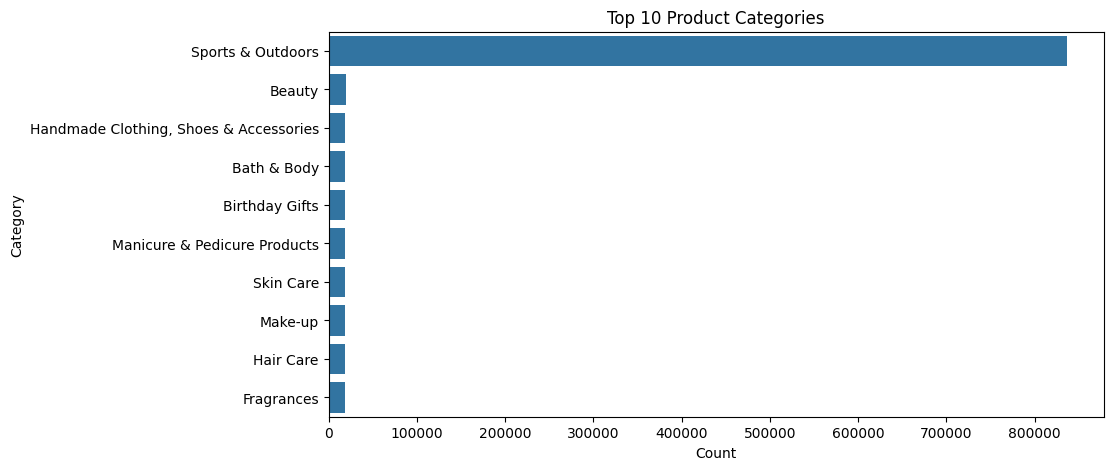

In [16]:
#Crear histograma

top_categories = df["category"].value_counts().head(10)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top 10 Product Categories")
plt.xlabel("Count")
plt.ylabel("Category")

plt.show()

In [18]:
#Part 2
#Calculate the mean, median, and mode for the price of products.

mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]
variance_price = df["price"].var()
std_price = df["price"].std()

mean_price, median_price, mode_price, variance_price, std_price

(np.float64(89.24380943923661),
 np.float64(19.09),
 np.float64(9.99),
 np.float64(119445.48532254901),
 np.float64(345.60886175349873))

What's the average price point of products listed? How does this compare with the most common price point (mode)?
El precio promedio es de 89.24 dolares y la moda de 9.99 dolares

In [ ]:
#Vamos a calcular el interquartile range. 
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)

iqr = q3 - q1

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

#El rango intercuartílico (IQR) es de £36, lo que indica que el 50% central de los productos tiene precios comprendidos entre aproximadamente £9.99 y £45.99. En comparación con la media (£89.24), esto sugiere la presencia de outliers con precios elevados que incrementan considerablemente el promedio general.

Q1: 9.99
Q3: 45.99
IQR: 36.0


In [22]:
filtered_df = df[df["price"] < 200]

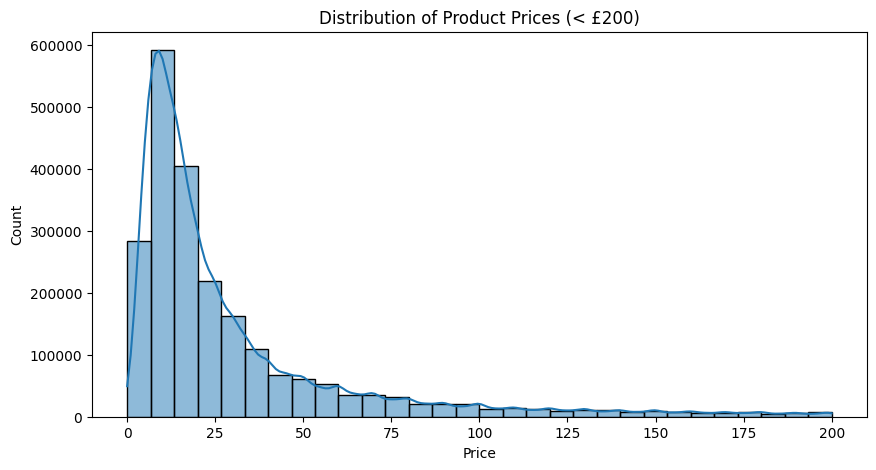

In [ ]:
#Visualizations
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

sns.histplot(
    filtered_df["price"],
    bins=30,
    kde=True
)

plt.title("Distribution of Product Prices (< £200)")
plt.xlabel("Price")
plt.ylabel("Count")

plt.show()

#Debido a la presencia de outliers extremos, el histograma original resultaba difícil de interpretar. Para visualizar mejor la distribución de la mayoría de productos, se excluyeron temporalmente del gráfico los precios superiores a £200. Esto mejora la legibilidad de la visualización sin modificar el dataset original.

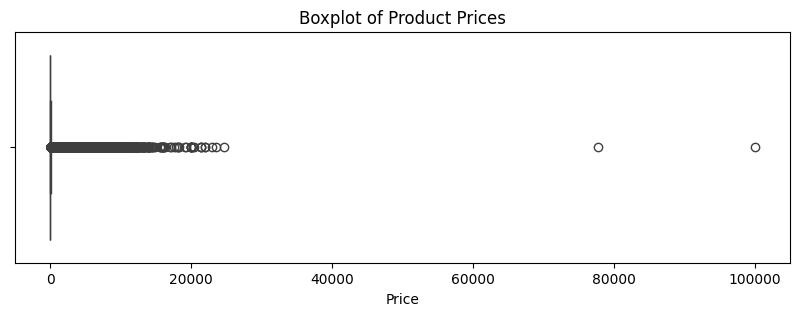

In [ ]:
plt.figure(figsize=(10,3))

sns.boxplot(x=df["price"])

plt.title("Boxplot of Product Prices")
plt.xlabel("Price")

plt.show()

#El boxplot muestra una distribución de precios fuertemente sesgada hacia la derecha, con numerosos outliers en los valores altos. La mayoría de productos se concentra en rangos de precios relativamente bajos, mientras que un pequeño grupo de productos presenta precios excepcionalmente elevados.

In [ ]:
#Part 3. 

mean_stars = df["stars"].mean()
median_stars = df["stars"].median()
mode_stars = df["stars"].mode()[0]
variance_stars = df["stars"].var()
std_stars = df["stars"].std()

mean_stars, median_stars, mode_stars, variance_stars, std_stars

#Los clientes valoran los productos con una media de 2.15/ 5. La moda es de 0, lo cual puede significar que falta la valoracion de muchos productos, estan sin rating

(np.float64(2.152836472966066),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(4.817434029796864),
 np.float64(2.194865378513421))

In [31]:
ratings_df = df[df["stars"] > 0]

In [ ]:
mean_stars = ratings_df["stars"].mean()
median_stars = ratings_df["stars"].median()
mode_stars = ratings_df["stars"].mode()[0]
variance_stars = ratings_df["stars"].var()
std_stars = ratings_df["stars"].std()

mean_stars, median_stars, mode_stars, variance_stars, std_stars

#Si consideramos solo los productos con valoracion de clientes, los resultados cambian. La valoracion media es de 4.32 y la moda es de 4.5/5

(np.float64(4.319160762226911),
 np.float64(4.4),
 np.float64(4.5),
 np.float64(0.3083433752387284),
 np.float64(0.5552867504620729))

In [ ]:
q1 = df["stars"].quantile(0.25)
q3 = df["stars"].quantile(0.75)

iqr = q3 - q1

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

#Las valoraciones muestran una elevada variabilidad, como indican tanto la desviación estándar (2.19) como el amplio rango intercuartílico (4.4). Sin embargo, esta dispersión probablemente está influenciada por la gran cantidad de productos con valoración 0, lo que podría representar productos sin reseñas en lugar de puntuaciones realmente bajas.

Q1: 0.0
Q3: 4.4
IQR: 4.4


In [ ]:
q1 = ratings_df["stars"].quantile(0.25)
q3 = ratings_df["stars"].quantile(0.75)

iqr = q3 - q1

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

#Después de excluir los productos con valoración 0, las puntuaciones muestran una alta consistencia. El rango intercuartílico es de solo 0.5, lo que indica que el 50% central de los productos tiene valoraciones entre 4.1 y 4.6 estrellas. Esto sugiere que la mayoría de productos valorados reciben opiniones positivas y bastante similares por parte de los clientes.

Q1: 4.1
Q3: 4.6
IQR: 0.5


In [ ]:
skewness = ratings_df["stars"].skew()
kurtosis = ratings_df["stars"].kurt()

print("Skewness:", skewness)
print("Kurtosis:", kurtosis)

#Las valoraciones no siguen una distribución normal y tienden a concentrarse en valores altos. Esto se refleja en la skewness negativa, lo que indica que la mayoría de productos recibe puntuaciones cercanas al extremo superior de la escala.

Skewness: -2.379568112212799
Kurtosis: 9.78193769066435


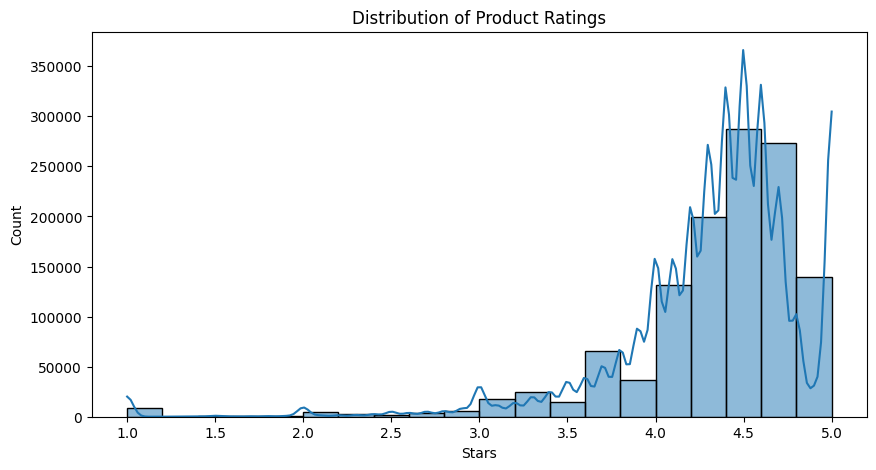

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

sns.histplot(
    ratings_df["stars"],
    bins=20,
    kde=True
)

plt.title("Distribution of Product Ratings")
plt.xlabel("Stars")
plt.ylabel("Count")

plt.show()

#El histograma muestra que las valoraciones se concentran principalmente entre 4 y 5 estrellas, siendo aproximadamente 4.5 la puntuación más frecuente. La distribución no es normal y está sesgada hacia valores altos, lo que indica que la mayoría de productos recibe opiniones positivas y que las valoraciones bajas son relativamente poco comunes.